# H20 — Brent crude oil forecasting

**Objective:** Forecast the Brent spot price 20 trading observations ahead and compare simple benchmarks with VAR, XGBoost and exploratory alternatives.

**Evaluation:** 2024–2025 validation; January–September 2026 test (both restricted by target date). Forecasts are generated at rolling origins using information available at each origin, subject to source publication timing. Model selection should use validation results, not test performance.

**Reproduction:** Run from the project `notebooks/` directory with the project environment and shared `src/` package. This notebook is a fresh H20 adaptation of the organized H15 workflow; the original H20 October experiments are retained separately.

In [1]:

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward

from src.models import (
    random_walk_forecast,
    historical_mean_forecast,
    ar1_forecast,
    var_forecast,
    xgb_forecast
)

from src.metrics import (
    accuracy_metrics,
    directional_metrics,
    compare_models
)

H = 20

print("H20 notebook ready!")


H20 notebook ready!


## 1. Data preparation and feature engineering

In [2]:

data = load_dataset()

X = pd.DataFrame(index=data.index)

for col in ["brent_spot", "wti", "usd", "sp500"]:
    X[col] = np.log(data[col].where(data[col] > 0)).diff()

for col in ["vix", "ovx", "epu", "gpr"]:
    X[col] = np.log(data[col].where(data[col] > 0))

X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

features_s1 = make_lag_features(
    df_var,
    cols=["log_return", "wti", "sp500"],
    lags=3
)

print("Cleaned observations:", len(df_var))
print("First date:", df_var.index.min())
print("Last date:", df_var.index.max())
print("XGBoost features:", features_s1.shape[1])


/Users/jingwen/Downloads/Sample-Taxed-main-2/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/jingwen/Downloads/Sample-Taxed-main-2/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/jingwen/Downloads/Sample-Taxed-main-2/.venv/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more

Cleaned observations: 4912
First date: 2007-05-10 00:00:00
Last date: 2026-10-27 00:00:00
XGBoost features: 9


## 2. Pre-validation diagnostics — ACF/PACF and ADF
Diagnostics use observations before January 2024; they are descriptive and do not establish a stable price equilibrium.

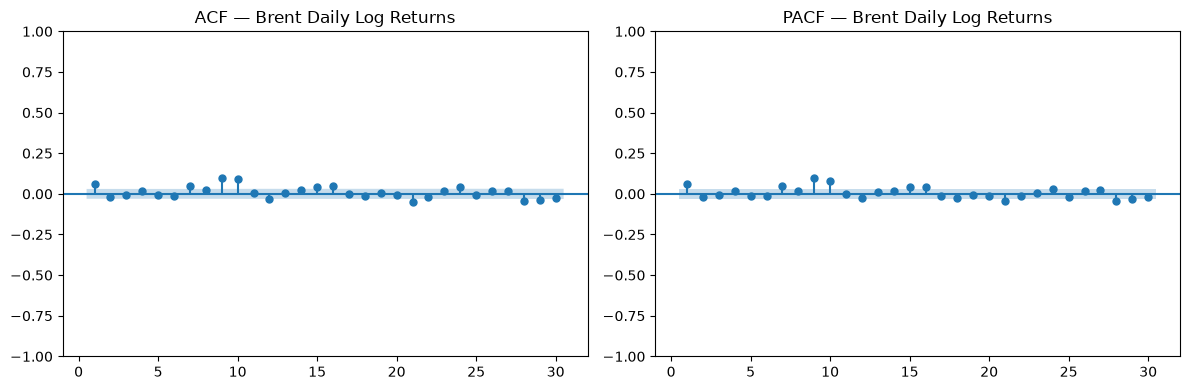

In [3]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pathlib import Path

returns = df_var.loc[
    df_var.index < "2024-01-01",
    "log_return"
].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    returns,
    lags=30,
    ax=axes[0],
    zero=False
)

plot_pacf(
    returns,
    lags=30,
    ax=axes[1],
    zero=False,
    method="ywm"
)

axes[0].set_title("ACF — Brent Daily Log Returns")
axes[1].set_title("PACF — Brent Daily Log Returns")

plt.tight_layout()

output_dir = Path("../results")
output_dir.mkdir(exist_ok=True)

plt.savefig(
    output_dir / "h20_acf_pacf.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [4]:

from statsmodels.tsa.stattools import adfuller
import numpy as np
import pandas as pd

train_data = df_var.loc[df_var.index < "2024-01-01"]

log_prices = np.log(
    train_data["brent_spot"]
).dropna()

returns = train_data["log_return"].dropna()

def run_adf(series, name):
    result = adfuller(
        series,
        autolag="AIC"
    )

    return {
        "Series": name,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Lags Used": result[2],
        "Observations": result[3],
        "Stationary at 5%": result[1] < 0.05
    }

adf_results = pd.DataFrame([
    run_adf(log_prices, "Brent log prices"),
    run_adf(returns, "Brent log returns")
])

display(adf_results)


/var/folders/zc/msw43vhx5n90s_3fp97cqxdw0000gn/T/ipykernel_13042/2369334279.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/var/folders/zc/msw43vhx5n90s_3fp97cqxdw0000gn/T/ipykernel_13042/2369334279.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


,Series,ADF Statistic,p-value,Lags Used,Observations,Stationary at 5%
0,Brent log prices,-3.038747,3.143100e-02,25,4171,True
1,Brent log returns,-11.652367,2.022943e-21,28,4168,True


## 3. Standardized rolling-origin evaluation
The backtest `end_date` is exclusive in the shared implementation; `target_end_date` is inclusive. Compare forecasts on identical target dates.

In [5]:

val_args = dict(
    horizon=H,
    start_date="2024-01-01",
    end_date="2025-12-31",
    target_end_date="2025-12-31"
)

test_args = dict(
    horizon=H,
    start_date="2026-01-01",
    end_date="2026-09-30",
    target_end_date="2026-09-30"
)

print("Validation and test periods configured.")


Validation and test periods configured.


In [6]:

rw_val = walk_forward(
    df=df_var,
    forecast_funct=random_walk_forecast,
    **val_args
)

rw_test = walk_forward(
    df=df_var,
    forecast_funct=random_walk_forecast,
    **test_args
)

print("Validation forecasts:", len(rw_val))
print("Test forecasts:", len(rw_test))

print("\nValidation accuracy:")
print(accuracy_metrics(rw_val))

print("\nTest accuracy:")
print(accuracy_metrics(rw_test))


Validation forecasts: 487
Test forecasts: 169

Validation accuracy:
{'MAE': np.float64(3.932032854209446), 'RMSE': np.float64(4.990628712764084), 'MAPE': np.float64(5.238922187746194)}

Test accuracy:
{'MAE': np.float64(17.330828402366862), 'RMSE': np.float64(21.227384024989483), 'MAPE': np.float64(17.81485333973021)}


## 4. Core model comparison
Random walk, historical mean, AR(1), VAR(3) on Brent/WTI/S&P 500 returns, and XGBoost S1. Keep these settings fixed when moving from validation to test.

In [7]:

# H20 validation model comparison

val_models = {
    "Random Walk": rw_val,

    "Historical Mean": walk_forward(
        df_var,
        forecast_funct=historical_mean_forecast,
        lookback=3000,
        **val_args
    ),

    "AR(1)": walk_forward(
        df_var,
        forecast_funct=ar1_forecast,
        lookback=3000,
        **val_args
    ),

    "VAR S1 p=3": walk_forward(
        df_var,
        forecast_funct=var_forecast,
        cols=["log_return", "wti", "sp500"],
        lags=3,
        lookback=3000,
        **val_args
    ),

    "XGBoost S1": walk_forward(
        df_var,
        forecast_funct=xgb_forecast,
        features=features_s1,
        lookback=3000,
        n_estimators=50,
        max_depth=1,
        learning_rate=0.05,
        min_child_weight=1,
        **val_args
    )
}

val_summary = compare_models(val_models, horizon=H)

display(
    val_summary[
        ["MAE", "RMSE", "MAPE", "directional_accuracy"]
    ].sort_values("MAPE")
)


,MAE,RMSE,MAPE,directional_accuracy
model,,,,
Random Walk,3.932033,4.990629,5.238922,0.000000
VAR S1 p=3,3.943408,5.018686,5.263307,0.494867
XGBoost S1,3.976157,5.030691,5.297335,0.546201
Historical Mean,3.979828,5.053137,5.312401,0.427105
AR(1),3.982897,5.062139,5.317050,0.420945


In [8]:

# H20 standardized test: January–September 2026

test_models = {
    "Random Walk": rw_test,

    "Historical Mean": walk_forward(
        df_var,
        forecast_funct=historical_mean_forecast,
        lookback=3000,
        **test_args
    ),

    "AR(1)": walk_forward(
        df_var,
        forecast_funct=ar1_forecast,
        lookback=3000,
        **test_args
    ),

    "VAR S1 p=3": walk_forward(
        df_var,
        forecast_funct=var_forecast,
        cols=["log_return", "wti", "sp500"],
        lags=3,
        lookback=3000,
        **test_args
    ),

    "XGBoost S1": walk_forward(
        df_var,
        forecast_funct=xgb_forecast,
        features=features_s1,
        lookback=3000,
        n_estimators=50,
        max_depth=1,
        learning_rate=0.05,
        min_child_weight=1,
        **test_args
    )
}

test_summary = compare_models(test_models, horizon=H)

display(
    test_summary[
        ["MAE", "RMSE", "MAPE", "directional_accuracy"]
    ].sort_values("MAPE")
)


,MAE,RMSE,MAPE,directional_accuracy
model,,,,
VAR S1 p=3,17.257111,21.129263,17.789087,0.508876
Random Walk,17.330828,21.227384,17.814853,0.000000
AR(1),17.330076,21.212058,17.837432,0.591716
Historical Mean,17.334323,21.222634,17.842239,0.644970
XGBoost S1,18.167842,22.079379,18.752753,0.337278


## 5. Exploratory extensions

ARIMA(4,1,1), SARIMA(1,1,1)(1,0,0,5), and direct WTI + USD regression are supplementary models. SARIMA tests a five-observation seasonal pattern, not an established seasonal effect. The earlier misaligned ARIMAX experiment is excluded.


In [9]:

from statsmodels.tsa.arima.model import ARIMA

print("ARIMA imported successfully!")


ARIMA imported successfully!


In [10]:

def arima_forecast(
    df,
    origin_idx,
    horizon,
    fit_idx,
    order=(4, 1, 1),
    lookback=750
):
    """
    Rolling-origin ARIMA forecast of Brent log prices.

    Fits only observations available at the forecast origin.
    Returns a price forecast horizon trading observations ahead.
    """

    if fit_idx > origin_idx:
        raise ValueError("fit_idx cannot exceed origin_idx")

    prices = df["brent_spot"].iloc[
        fit_idx - lookback + 1:fit_idx + 1
    ]

    if len(prices) < lookback or (prices <= 0).any():
        raise ValueError("Invalid ARIMA training window")

    log_prices = np.log(prices)

    model = ARIMA(
        log_prices.to_numpy(),
        order=order,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit()

    predicted_log_price = fitted.forecast(
        steps=horizon
    )[-1]

    return float(np.exp(predicted_log_price))


print("ARIMA forecasting function ready!")


ARIMA forecasting function ready!


In [11]:

import warnings
import time

start_time = time.time()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    arima20_val = walk_forward(
        df=df_var,
        forecast_funct=arima_forecast,
        order=(4, 1, 1),
        lookback=750,
        **val_args
    )

print("ARIMA forecasts:", len(arima20_val))
print("Elapsed seconds:", round(time.time() - start_time, 1))

print("\nARIMA H20 validation:")
print(accuracy_metrics(arima20_val))

print("\nRandom walk H20 validation:")
print(accuracy_metrics(rw_val))


ARIMA forecasts: 487
Elapsed seconds: 48.0

ARIMA H20 validation:
{'MAE': np.float64(3.929754800705261), 'RMSE': np.float64(4.982447567424104), 'MAPE': np.float64(5.235411471920613)}

Random walk H20 validation:
{'MAE': np.float64(3.932032854209446), 'RMSE': np.float64(4.990628712764084), 'MAPE': np.float64(5.238922187746194)}


In [12]:

assert len(arima20_val) == len(rw_val)

assert (
    arima20_val["target_date"].reset_index(drop=True)
    .equals(
        rw_val["target_date"].reset_index(drop=True)
    )
)

print("ARIMA and Random Walk target dates aligned.")


ARIMA and Random Walk target dates aligned.


In [13]:

import time
import warnings

start_time = time.time()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    arima20_test = walk_forward(
        df=df_var,
        forecast_funct=arima_forecast,
        order=(4, 1, 1),
        lookback=750,
        **test_args
    )

print("Test forecasts:", len(arima20_test))
print("Elapsed seconds:", round(time.time() - start_time, 1))

print("\nARIMA H20 test:")
print(accuracy_metrics(arima20_test))

print("\nRandom Walk H20 test:")
print(accuracy_metrics(rw_test))


Test forecasts: 169
Elapsed seconds: 16.2

ARIMA H20 test:
{'MAE': np.float64(17.382008535304813), 'RMSE': np.float64(21.272134376399904), 'MAPE': np.float64(17.86809344052472)}

Random Walk H20 test:
{'MAE': np.float64(17.330828402366862), 'RMSE': np.float64(21.227384024989483), 'MAPE': np.float64(17.81485333973021)}


In [14]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import warnings
import time

def sarima_forecast(
    df,
    origin_idx,
    horizon,
    fit_idx,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 0, 5),
    lookback=750
):
    if fit_idx > origin_idx:
        raise ValueError("Future fitting date detected")

    start = fit_idx - lookback + 1

    if start < 0:
        raise ValueError("Insufficient history")

    prices = df["brent_spot"].iloc[
        start:fit_idx + 1
    ]

    if prices.isna().any() or (prices <= 0).any():
        raise ValueError("Invalid price observations")

    log_prices = np.log(prices.to_numpy())

    model = SARIMAX(
        log_prices,
        order=order,
        seasonal_order=seasonal_order,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False, maxiter=100)

    predicted_log_price = fitted.forecast(
        steps=horizon
    )[-1]

    return float(np.exp(predicted_log_price))

print("H20 SARIMA function ready!")


H20 SARIMA function ready!


In [15]:

start_time = time.time()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    sarima20_val = walk_forward(
        df=df_var,
        forecast_funct=sarima_forecast,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 0, 5),
        lookback=750,
        **val_args
    )

print("SARIMA forecasts:", len(sarima20_val))
print("Elapsed seconds:", round(time.time() - start_time, 1))

print("\nSARIMA H20 validation:")
print(accuracy_metrics(sarima20_val))

print("\nRandom Walk H20 validation:")
print(accuracy_metrics(rw_val))

print("\nARIMA H20 validation:")
print(accuracy_metrics(arima20_val))


SARIMA forecasts: 487
Elapsed seconds: 62.9

SARIMA H20 validation:
{'MAE': np.float64(3.921403422659477), 'RMSE': np.float64(4.9762128468295055), 'MAPE': np.float64(5.2227115562812)}

Random Walk H20 validation:
{'MAE': np.float64(3.932032854209446), 'RMSE': np.float64(4.990628712764084), 'MAPE': np.float64(5.238922187746194)}

ARIMA H20 validation:
{'MAE': np.float64(3.929754800705261), 'RMSE': np.float64(4.982447567424104), 'MAPE': np.float64(5.235411471920613)}


In [16]:

assert len(sarima20_val) == len(rw_val)

assert (
    sarima20_val["target_date"].reset_index(drop=True)
    .equals(
        rw_val["target_date"].reset_index(drop=True)
    )
)

print("SARIMA and Random Walk dates aligned.")


SARIMA and Random Walk dates aligned.


In [17]:

# H20 SARIMA — standardized test period

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    sarima20_test = walk_forward(
        df=df_var,
        forecast_funct=sarima_forecast,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 0, 5),
        lookback=750,
        **test_args
    )

print("SARIMA test forecasts:", len(sarima20_test))

print("\nSARIMA H20 test:")
print(accuracy_metrics(sarima20_test))

print("\nRandom Walk H20 test:")
print(accuracy_metrics(rw_test))

print("\nARIMA H20 test:")
print(accuracy_metrics(arima20_test))

assert (
    sarima20_test["target_date"].reset_index(drop=True)
    .equals(rw_test["target_date"].reset_index(drop=True))
)

print("\nSARIMA test dates aligned.")


SARIMA test forecasts: 169

SARIMA H20 test:
{'MAE': np.float64(17.344295251848525), 'RMSE': np.float64(21.23840254541118), 'MAPE': np.float64(17.827123063644827)}

Random Walk H20 test:
{'MAE': np.float64(17.330828402366862), 'RMSE': np.float64(21.227384024989483), 'MAPE': np.float64(17.81485333973021)}

ARIMA H20 test:
{'MAE': np.float64(17.382008535304813), 'RMSE': np.float64(21.272134376399904), 'MAPE': np.float64(17.86809344052472)}

SARIMA test dates aligned.


In [18]:

from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd
import time

def direct_wti_usd_forecast(
    df,
    origin_idx,
    horizon,
    fit_idx,
    lookback=750
):
    """
    Direct H-day Brent return regression.

    Predictors:
      - Past 5-day WTI cumulative log return
      - Past 5-day USD cumulative log return

    Uses only training targets fully observed by fit_idx.
    """

    if fit_idx > origin_idx:
        raise ValueError("Future fitting date detected")

    # Historical predictor info
    X = pd.DataFrame(index=df.index)

    X["wti_5d"] = df["wti"].rolling(5).sum()
    X["usd_5d"] = df["usd"].rolling(5).sum()

    # Future H-day Brent log return
    log_price = np.log(df["brent_spot"])

    y = log_price.shift(-horizon) - log_price

    # Latest training origin with a fully observed target
    train_end = fit_idx - horizon

    train_start = max(
        0,
        train_end - lookback + 1
    )

    X_train = X.iloc[
        train_start:train_end + 1
    ]

    y_train = y.iloc[
        train_start:train_end + 1
    ]

    valid = (
        X_train.notna().all(axis=1)
        & y_train.notna()
    )

    X_train = X_train.loc[valid]
    y_train = y_train.loc[valid]

    if len(y_train) < 100:
        raise ValueError("Insufficient training observations")

    model = LinearRegression()

    model.fit(
        X_train.to_numpy(),
        y_train.to_numpy()
    )

    # Predictors available at forecast origin
    X_current = X.iloc[
        origin_idx:origin_idx + 1
    ]

    if X_current.isna().any().any():
        raise ValueError("Missing current predictors")

    predicted_return = model.predict(
        X_current.to_numpy()
    )[0]

    origin_price = df["brent_spot"].iloc[origin_idx]

    return float(
        origin_price * np.exp(predicted_return)
    )

print("Direct WTI + USD regression ready!")


Direct WTI + USD regression ready!


In [19]:

start_time = time.time()

direct_wti_usd_val = walk_forward(
    df=df_var,
    forecast_funct=direct_wti_usd_forecast,
    lookback=750,
    **val_args
)

print("Forecasts:", len(direct_wti_usd_val))
print(
    "Elapsed seconds:",
    round(time.time() - start_time, 1)
)

print("\nDirect WTI + USD validation:")
print(accuracy_metrics(direct_wti_usd_val))

print("\nRandom Walk validation:")
print(accuracy_metrics(rw_val))

print("\nARIMA validation:")
print(accuracy_metrics(arima20_val))


Forecasts: 487
Elapsed seconds: 1.0

Direct WTI + USD validation:
{'MAE': np.float64(3.8127454636896334), 'RMSE': np.float64(4.934852906382627), 'MAPE': np.float64(5.073308866853586)}

Random Walk validation:
{'MAE': np.float64(3.932032854209446), 'RMSE': np.float64(4.990628712764084), 'MAPE': np.float64(5.238922187746194)}

ARIMA validation:
{'MAE': np.float64(3.929754800705261), 'RMSE': np.float64(4.982447567424104), 'MAPE': np.float64(5.235411471920613)}


In [20]:

assert len(direct_wti_usd_val) == len(rw_val)

assert (
    direct_wti_usd_val["target_date"].reset_index(drop=True)
    .equals(
        rw_val["target_date"].reset_index(drop=True)
    )
)

print("Direct regression and Random Walk dates aligned.")


Direct regression and Random Walk dates aligned.


In [21]:

direct_wti_usd_test = walk_forward(
    df=df_var,
    forecast_funct=direct_wti_usd_forecast,
    lookback=750,
    **test_args
)

print("Test forecasts:", len(direct_wti_usd_test))

print("\nDirect WTI + USD test:")
print(accuracy_metrics(direct_wti_usd_test))

print("\nRandom Walk test:")
print(accuracy_metrics(rw_test))

print("\nARIMA test:")
print(accuracy_metrics(arima20_test))


Test forecasts: 169

Direct WTI + USD test:
{'MAE': np.float64(17.947165425258497), 'RMSE': np.float64(22.081848028389818), 'MAPE': np.float64(18.468225641151857)}

Random Walk test:
{'MAE': np.float64(17.330828402366862), 'RMSE': np.float64(21.227384024989483), 'MAPE': np.float64(17.81485333973021)}

ARIMA test:
{'MAE': np.float64(17.382008535304813), 'RMSE': np.float64(21.272134376399904), 'MAPE': np.float64(17.86809344052472)}


## 6. Consolidated H20 forecast metrics and test-period plot
The plot uses **test target dates**, not the original October-only evaluation. The CSV files contain newly generated H20 forecasts.

In [22]:
from pathlib import Path
output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

In [23]:
# Final consolidated comparison; uses previously computed forecasts
final_validation = {**val_models, "ARIMA(4,1,1)": arima20_val,
                    "Direct WTI + USD": direct_wti_usd_val,
                    "SARIMA(1,1,1)(1,0,0,5)": sarima20_val}
final_test = {**test_models, "ARIMA(4,1,1)": arima20_test,
              "Direct WTI + USD": direct_wti_usd_test,
              "SARIMA(1,1,1)(1,0,0,5)": sarima20_test}

rows = []
for name in final_validation:
    val = accuracy_metrics(final_validation[name])
    test = accuracy_metrics(final_test[name])
    rows.append({"Model": name, "Validation MAE": val["MAE"],
                 "Validation RMSE": val["RMSE"], "Validation MAPE (%)": val["MAPE"],
                 "Test MAE": test["MAE"], "Test RMSE": test["RMSE"],
                 "Test MAPE (%)": test["MAPE"]})
final_summary = pd.DataFrame(rows).sort_values("Validation MAPE (%)")
display(final_summary.round(4))
final_summary.to_csv(output_dir / "h20_all_model_metrics.csv", index=False)
print("Saved consolidated H20 metrics.")


,Model,Validation MAE,Validation RMSE,Validation MAPE (%),Test MAE,Test RMSE,Test MAPE (%)
6,Direct WTI + USD,3.8127,4.9349,5.0733,17.9472,22.0818,18.4682
7,"SARIMA(1,1,1)(1,0,0,5)",3.9214,4.9762,5.2227,17.3443,21.2384,17.8271
5,"ARIMA(4,1,1)",3.9298,4.9824,5.2354,17.3820,21.2721,17.8681
0,Random Walk,3.9320,4.9906,5.2389,17.3308,21.2274,17.8149
3,VAR S1 p=3,3.9434,5.0187,5.2633,17.2571,21.1293,17.7891
4,XGBoost S1,3.9762,5.0307,5.2973,18.1678,22.0794,18.7528
1,Historical Mean,3.9798,5.0531,5.3124,17.3343,21.2226,17.8422
2,AR(1),3.9829,5.0621,5.3170,17.3301,21.2121,17.8374


Saved consolidated H20 metrics.


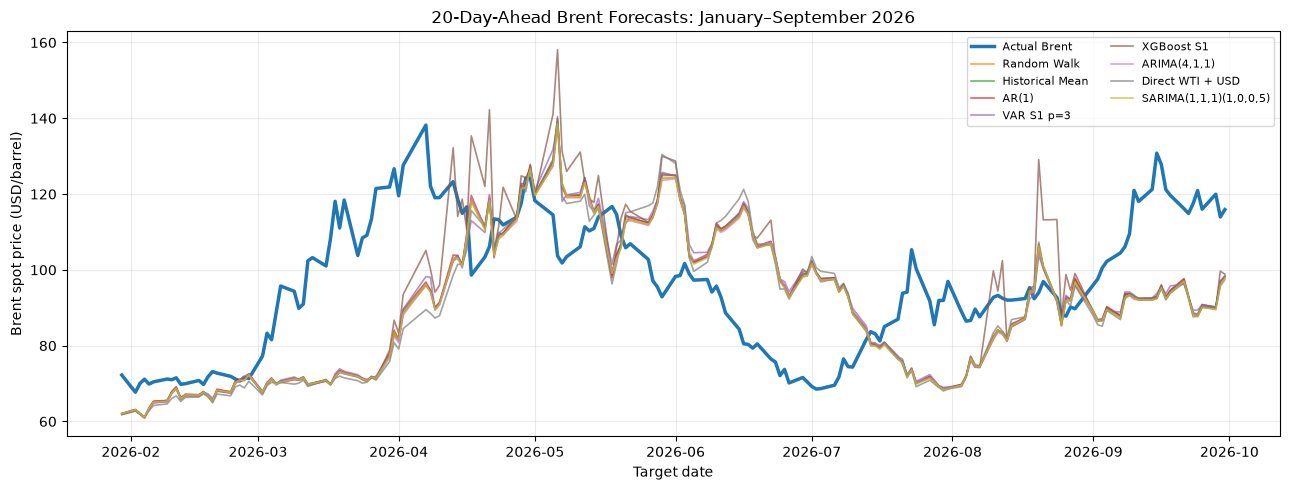

Saved H20 test chart and forecast CSVs.


In [24]:
from pathlib import Path
import re
output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

# Verify exact alignment with the random-walk benchmark
for name, forecasts in final_test.items():
    assert len(forecasts) == len(rw_test), f"Count mismatch: {name}"
    assert forecasts["target_date"].reset_index(drop=True).equals(
        rw_test["target_date"].reset_index(drop=True)
    ), f"Date mismatch: {name}"
    assert np.allclose(forecasts["actual"], rw_test["actual"]), name

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(rw_test["target_date"], rw_test["actual"], label="Actual Brent", linewidth=2.5)
for name in final_test:
    ax.plot(final_test[name]["target_date"], final_test[name]["forecast"],
            label=name, alpha=0.72, linewidth=1.2)
ax.set(title="20-Day-Ahead Brent Forecasts: January–September 2026",
       xlabel="Target date", ylabel="Brent spot price (USD/barrel)")
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / "h20_test_comparison.png", dpi=200)
plt.show()
for name, forecasts in final_test.items():
    slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    forecasts.to_csv(output_dir / f"h20_{slug}_test.csv", index=False)
print("Saved H20 test chart and forecast CSVs.")

## 7. Forecast accuracy significance — exploratory DM-style test
Absolute-error loss differentials with Bartlett HAC lags H−1 account approximately for overlapping horizons. P-values are exploratory because of repeated model selection and dependent observations.

In [25]:

import numpy as np
import pandas as pd
from scipy.stats import norm

def dm_test(rw, challenger, horizon=20, loss="absolute"):
    """
    DM-style equal predictive accuracy test.

    Positive DM statistic means challenger has
    lower average loss than random walk.

    HAC variance uses Bartlett weights
    and horizon - 1 lags.
    """

    keys = ["origin_date", "target_date"]

    a = rw[keys + ["actual", "forecast"]].merge(
        challenger[keys + ["actual", "forecast"]],
        on=keys,
        suffixes=("_rw", "_model"),
        validate="one_to_one"
    ).sort_values(keys).reset_index(drop=True)

    if len(a) != len(rw) or len(a) != len(challenger):
        raise ValueError("Forecast dates do not fully align")

    if not np.allclose(a["actual_rw"], a["actual_model"]):
        raise ValueError("Actual prices do not match")

    e_rw = a["actual_rw"].to_numpy() - a["forecast_rw"].to_numpy()
    e_model = a["actual_model"].to_numpy() - a["forecast_model"].to_numpy()

    if loss == "absolute":
        d = np.abs(e_rw) - np.abs(e_model)
    elif loss == "squared":
        d = e_rw**2 - e_model**2
    else:
        raise ValueError("loss must be absolute or squared")

    n = len(d)
    lag = min(horizon - 1, n - 1)

    centered = d - d.mean()

    # HAC long-run variance with Bartlett weights
    long_run_var = np.dot(centered, centered) / n

    for k in range(1, lag + 1):
        gamma_k = np.dot(
            centered[k:], centered[:-k]
        ) / n

        weight = 1 - k / (lag + 1)

        long_run_var += 2 * weight * gamma_k

    if long_run_var <= 0:
        raise ValueError("Non-positive HAC variance")

    dm_stat = d.mean() / np.sqrt(long_run_var / n)
    p_value = 2 * norm.sf(abs(dm_stat))

    return {
        "N": n,
        "Mean loss advantage": d.mean(),
        "DM statistic": dm_stat,
        "p-value": p_value
    }

print("DM test function ready!")


DM test function ready!


In [26]:

#DM tests
dm_validation = pd.DataFrame({
    "Direct WTI + USD": dm_test(
        rw_val, direct_wti_usd_val, horizon=H
    ),
    "ARIMA(4,1,1)": dm_test(
        rw_val, arima20_val, horizon=H
    ),
    "XGBoost S1": dm_test(
        rw_val, val_models["XGBoost S1"], horizon=H
    )
}).T

display(dm_validation.round(5))


,N,Mean loss advantage,DM statistic,p-value
Direct WTI + USD,487.0,0.11929,1.37868,0.16799
"ARIMA(4,1,1)",487.0,0.00228,0.26155,0.79367
XGBoost S1,487.0,-0.04412,-1.30869,0.19064


In [27]:

# H20 test-period DM comparisons

dm_test_results = pd.DataFrame({
    "Direct WTI + USD": dm_test(
        rw_test, direct_wti_usd_test, horizon=H
    ),
    "ARIMA(4,1,1)": dm_test(
        rw_test, arima20_test, horizon=H
    ),
    "Historical Mean": dm_test(
        rw_test,
        test_models["Historical Mean"],
        horizon=H
    )
}).T

display(dm_test_results.round(5))


,N,Mean loss advantage,DM statistic,p-value
Direct WTI + USD,169.0,-0.61634,-2.48731,0.01287
"ARIMA(4,1,1)",169.0,-0.05118,-2.02632,0.04273
Historical Mean,169.0,-0.00349,-0.03292,0.97374


In [28]:

# H20 SARIMA vs Random Walk — DM-style comparisons

sarima_dm = pd.DataFrame({
    "Validation": dm_test(
        rw_val,
        sarima20_val,
        horizon=20
    ),
    "Test": dm_test(
        rw_test,
        sarima20_test,
        horizon=20
    )
}).T

display(sarima_dm.round(5))


,N,Mean loss advantage,DM statistic,p-value
Validation,487.0,0.01063,1.03942,0.29861
Test,169.0,-0.01347,-0.77044,0.44104


## 8. Economic validity and sensitivity
Illustrative spot-return long/short trading, **not** executable futures P&L. Non-overlapping origin schedules can yield very few trades; report the range across all offsets and compare with always-long.

In [29]:

import numpy as np
import pandas as pd

economic_models = {
    **test_models,
    "ARIMA(4,1,1)": arima20_test,
    "SARIMA(1,1,1)(1,0,0,5)": sarima20_test
}

def economic_backtest(results, horizon=20, cost=0.0005, offset=0):
    """
    Simplified non-overlapping directional strategy.
    Long if forecast > origin price.
    Short if forecast < origin price.
    Flat otherwise.

    cost = 0.0005 per unit of position turnover.
    """

    trades = results.iloc[offset::horizon].copy()

    if trades.empty:
        raise ValueError("No trades for this offset")

    trades["position"] = np.sign(
        trades["forecast"] - trades["origin_price"]
    )

    trades["market_return"] = (
        trades["actual"] / trades["origin_price"] - 1
    )

    trades["gross_return"] = (
        trades["position"] * trades["market_return"]
    )

    previous_position = trades["position"].shift().fillna(0)

    # Entry/exit turnover; charge for final liquidation too
    trades["turnover"] = (
        trades["position"] - previous_position
    ).abs()

    trades["net_return"] = (
        trades["gross_return"] - cost * trades["turnover"]
    )

    # Final exit cost
    trades.iloc[-1, trades.columns.get_loc("net_return")] -= (
        cost * abs(trades["position"].iloc[-1])
    )

    trades["wealth"] = (1 + trades["net_return"]).cumprod()
    trades["drawdown"] = (
        trades["wealth"] / trades["wealth"].cummax().clip(lower=1)
        - 1
    )

    periods_per_year = 252 / horizon

    vol = trades["net_return"].std(ddof=1)

    sharpe = (
        trades["net_return"].mean() / vol
        * np.sqrt(periods_per_year)
        if pd.notna(vol) and vol > 0
        else np.nan
    )

    return {
        "trades": len(trades),
        "total_return": trades["wealth"].iloc[-1] - 1,
        "sharpe": sharpe,
        "max_drawdown": trades["drawdown"].min(),
        "win_rate": (trades["net_return"] > 0).mean()
    }


economic_summary = pd.DataFrame({
    name: economic_backtest(results, horizon=H)
    for name, results in economic_models.items()
}).T

display(economic_summary.round(4))


,trades,total_return,sharpe,max_drawdown,win_rate
Random Walk,9.0,0.0000,NaN,0.0000,0.0000
Historical Mean,9.0,0.9290,1.2744,-0.3929,0.4444
AR(1),9.0,0.9290,1.2744,-0.3929,0.4444
VAR S1 p=3,9.0,0.0161,0.5038,-0.6426,0.5556
XGBoost S1,9.0,-0.9016,-2.2488,-0.9226,0.2222
"ARIMA(4,1,1)",9.0,-0.6939,-0.5894,-0.7404,0.5556
"SARIMA(1,1,1)(1,0,0,5)",9.0,0.3341,0.8382,-0.4931,0.6667


In [30]:

# Check all H possible non-overlapping starting offsets

rows = []

for name, results in economic_models.items():
    for offset in range(H):
        metrics = economic_backtest(
            results,
            horizon=H,
            offset=offset
        )

        rows.append({
            "model": name,
            "offset": offset,
            **metrics
        })

offset_results = pd.DataFrame(rows)

offset_summary = offset_results.groupby("model").agg(
    mean_sharpe=("sharpe", "mean"),
    min_sharpe=("sharpe", "min"),
    max_sharpe=("sharpe", "max"),
    mean_total_return=("total_return", "mean"),
    mean_max_drawdown=("max_drawdown", "mean")
)

display(offset_summary.round(4))


,mean_sharpe,min_sharpe,max_sharpe,mean_total_return,mean_max_drawdown
model,,,,,
AR(1),1.0607,-0.3138,2.0245,0.5490,-0.4204
"ARIMA(4,1,1)",-0.1961,-1.9282,1.4028,-0.2642,-0.5595
Historical Mean,1.3402,1.1795,1.5711,0.7485,-0.3772
Random Walk,NaN,NaN,NaN,0.0000,0.0000
"SARIMA(1,1,1)(1,0,0,5)",0.0003,-1.9013,1.9911,-0.0858,-0.5192
VAR S1 p=3,0.1411,-5.1763,3.8792,0.2807,-0.5174
XGBoost S1,-1.0474,-2.2488,-0.2192,-0.5872,-0.6937


In [31]:

# Overlap check
for name, results in economic_models.items():

    trades = results.iloc[::H].copy().reset_index(drop=True)

    overlaps = (
        trades["target_date"].iloc[:-1].to_numpy()
        > trades["origin_date"].iloc[1:].to_numpy()
    )

    print(
        name,
        "| trades:", len(trades),
        "| overlapping periods:", overlaps.sum()
    )


Random Walk | trades: 9 | overlapping periods: 0
Historical Mean | trades: 9 | overlapping periods: 0
AR(1) | trades: 9 | overlapping periods: 0
VAR S1 p=3 | trades: 9 | overlapping periods: 0
XGBoost S1 | trades: 9 | overlapping periods: 0
ARIMA(4,1,1) | trades: 9 | overlapping periods: 0
SARIMA(1,1,1)(1,0,0,5) | trades: 9 | overlapping periods: 0


In [32]:

# Always-long benchmark using the same holding periods

always_long_results = rw_test.copy()

always_long_results["forecast"] = (
    always_long_results["origin_price"] * 1.01
)

benchmark_rows = []

for offset in range(H):
    metrics = economic_backtest(
        always_long_results,
        horizon=H,
        offset=offset
    )

    benchmark_rows.append({
        "offset": offset,
        **metrics
    })

always_long_summary = pd.DataFrame(benchmark_rows)

display(
    always_long_summary[
        ["offset", "trades", "total_return", "sharpe", "max_drawdown"]
    ].round(4)
)

print(
    "Mean always-long Sharpe:",
    round(always_long_summary["sharpe"].mean(), 4)
)


,offset,trades,total_return,sharpe,max_drawdown
0,0,9,0.9290,1.2744,-0.3929
1,1,9,0.8420,1.2918,-0.4349
2,2,9,0.8485,1.3782,-0.4349
3,3,9,0.9213,1.4926,-0.4107
4,4,9,0.9075,1.4023,-0.4574
5,5,9,0.7802,1.2790,-0.5042
6,6,9,0.8329,1.3573,-0.4376
7,7,9,0.6848,1.3513,-0.4156
8,8,9,0.6815,1.3996,-0.3972
9,9,8,0.5180,1.1795,-0.3795


Mean always-long Sharpe: 1.3402


## 9. Volatility and forecast-error diagnostics
The full-period realized volatility is known only ex post. Ljung–Box applied to overlapping H20 forecast errors is expected to reject independence and is not a standard one-step innovation test.

In [33]:
val_returns = df_var.loc[
    "2024-01-01":"2025-12-31", "log_return"
]

test_returns = df_var.loc[
    "2026-01-01":"2026-09-30", "log_return"
]

vol_comparison = pd.DataFrame({
    "Period": ["Validation 2024-2025", "Test 2026"],
    "Daily volatility": [
        val_returns.std(),
        test_returns.std()
    ],
    "Annualized volatility": [
        val_returns.std() * np.sqrt(252),
        test_returns.std() * np.sqrt(252)
    ]
})

display(vol_comparison)

print(
    "Test/validation daily volatility ratio:",
    round(test_returns.std() / val_returns.std(), 2)
)


,Period,Daily volatility,Annualized volatility
0,Validation 2024-2025,0.018063,0.286738
1,Test 2026,0.043186,0.685560


Test/validation daily volatility ratio: 2.39


In [34]:

from statsmodels.stats.diagnostic import acorr_ljungbox

errors = (
    direct_wti_usd_val["actual"].to_numpy()
    - direct_wti_usd_val["forecast"].to_numpy()
)

lb_results = acorr_ljungbox(
    errors,
    lags=[5, 10, 15, 20],
    return_df=True
)

display(lb_results)


,lb_stat,lb_pvalue
5,1429.634809,5.215706e-307
10,1828.037653,0.000000e+00
15,1912.341163,0.000000e+00
20,2004.428300,0.000000e+00


## Additional economic comparison — group-standard staggered backtest (H20)

This section uses a self-contained copy of the group’s `compare_models_staggered` methodology, matching the economic-return convention used by the H30/H60 notebooks. Every forecast origin opens a position, and the portfolio holds up to 20 staggered signals. The reported Sharpe is annualized from daily net portfolio returns.

This is **additional** to the earlier non-overlapping/offset robustness analysis, not a replacement. The group function charges 0.01% per unit change in net exposure; the earlier offset backtest uses a different cost assumption. Results should not be interpreted as executable futures trading P&L. The random-walk no-change strategy is flat, so its Sharpe is undefined.


In [35]:
import numpy as np
import pandas as pd

# Self-contained copy of the group's staggered convention.
# This avoids depending on an older local src.metrics module.
def economic_value_staggered_local(results, horizon, transaction_cost=0.0001):
    px = pd.concat([
        results.set_index("origin_date")["origin_price"],
        results.set_index("target_date")["actual"]
    ])
    px = px[~px.index.duplicated()].sort_index()
    ret = px.pct_change()
    sig = np.sign(results["forecast"] - results["origin_price"])
    sig.index = results["origin_date"]
    sig = sig.reindex(px.index)
    exposure = sig.shift(1).rolling(horizon).mean()
    turnover = exposure.diff().abs()
    net = exposure * ret - transaction_cost * turnover
    full = sig.notna().to_numpy() & exposure.notna().to_numpy()
    net = net[full].iloc[1:]
    exposure = exposure[full].iloc[1:]
    turnover = turnover[full].iloc[1:]
    ann_ret = net.mean() * 252
    ann_vol = net.std() * np.sqrt(252)
    equity = (1 + net).cumprod()
    return {
        "annualized_return": ann_ret,
        "annualized_vol": ann_vol,
        "sharpe_ratio": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "max_drawdown": (equity / equity.cummax() - 1).min(),
        "avg_gross_exposure": exposure.abs().mean(),
        "pct_time_net_long": (exposure > 0).mean(),
        "annual_turnover": turnover.mean() * 252,
        "n_days": len(net),
    }

def compare_models_staggered_local(results_dict, horizon):
    return pd.DataFrame({
        name: economic_value_staggered_local(frame, horizon)
        for name, frame in results_dict.items()
    }).T


# Same test forecasts already computed above; no model refitting.
staggered_models = {
    **test_models,
    "ARIMA(4,1,1)": arima20_test,
    "SARIMA(1,1,1)(1,0,0,5)": sarima20_test,
    "Direct WTI + USD": direct_wti_usd_test,
}

# Confirm matching dates and prices across models.
reference = staggered_models["Random Walk"].reset_index(drop=True)
for name, frame in staggered_models.items():
    candidate = frame.reset_index(drop=True)
    assert len(candidate) == len(reference), name
    assert candidate["origin_date"].equals(reference["origin_date"]), name
    assert candidate["target_date"].equals(reference["target_date"]), name
    assert np.allclose(candidate["actual"], reference["actual"]), name

# Benchmark for market exposure: always long.
always_long_staggered = reference.copy()
always_long_staggered["forecast"] = always_long_staggered["origin_price"] * 1.01
staggered_models["Always Long"] = always_long_staggered

staggered_summary = compare_models_staggered_local(
    staggered_models,
    horizon=20
)
display(staggered_summary[[
    "annualized_return", "annualized_vol", "sharpe_ratio",
    "max_drawdown", "annual_turnover", "avg_gross_exposure", "n_days"
]].round(4))

# The group implementation assumes a consecutive trading-day path.
# Confirm the reconstructed path matches the cleaned dataset.
px = pd.concat([
    reference.set_index("origin_date")["origin_price"],
    reference.set_index("target_date")["actual"]
])
px = px[~px.index.duplicated()].sort_index()
expected = df_var["brent_spot"].reindex(px.index)
assert np.allclose(px.to_numpy(), expected.to_numpy(), equal_nan=False)
print("Staggered portfolio path aligned with cleaned Brent data.")


,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,annual_turnover,avg_gross_exposure,n_days
Random Walk,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,148.0
Historical Mean,0.7760,0.7270,1.0675,-0.5042,0.0000,1.0000,148.0
AR(1),0.5245,0.6011,0.8725,-0.4537,4.7676,0.8162,148.0
VAR S1 p=3,-0.0718,0.2985,-0.2404,-0.3469,9.8757,0.4365,148.0
XGBoost S1,-1.1351,0.4917,-2.3086,-0.5977,9.5351,0.7378,148.0
"ARIMA(4,1,1)",-0.0762,0.1865,-0.4087,-0.2156,13.1108,0.2297,148.0
"SARIMA(1,1,1)(1,0,0,5)",-0.0287,0.2405,-0.1193,-0.1988,13.6216,0.2642,148.0
Direct WTI + USD,-1.0583,0.3178,-3.3305,-0.5114,11.7486,0.3574,148.0
Always Long,0.7760,0.7270,1.0675,-0.5042,0.0000,1.0000,148.0


Staggered portfolio path aligned with cleaned Brent data.


## 11. Final interpretation and limitations

**Forecast accuracy.** The H20 evaluation contains 487 validation and 169 test forecasts. Direct WTI + USD achieved the lowest exploratory validation MAPE (5.0733%, versus 5.2389% for random walk), but its test MAPE was 18.4682% versus 17.8149% for random walk. SARIMA(1,1,1)(1,0,0,5) recorded validation/test MAPE of 5.2227%/17.8271%; ARIMA(4,1,1) recorded 5.2354%/17.8681%. VAR(3) had the lowest *observed* test MAPE (17.7891%), but this is a retrospective ranking, not an ex-ante selection rule. SARIMA versus random-walk DM-style tests did not reject equal average absolute forecast loss (validation p=0.2986, test p=0.4410).

**Economic validity.** Under the group's *daily staggered* strategy (148 daily portfolio-return observations), historical mean had Sharpe 1.0675, identical to always-long (1.0675). AR(1) achieved 0.8725, while VAR, XGBoost, ARIMA, SARIMA and direct WTI + USD produced negative staggered Sharpe ratios. No demonstrated incremental economic value over simple long exposure emerges. The earlier *non-overlapping* offset analysis remains a separate robustness check and uses a different trading convention and cost assumption.

**Robustness and limitations.** H20 forecasts overlap, and the 2026 test period has been examined repeatedly; DM-style p-values are exploratory and unadjusted for model search. The spot-return trading simulation assumes daily netted exposures and 0.01% cost per unit of net exposure change, omitting futures rolls, financing and execution frictions. Reported annualized return is an arithmetic approximation rather than compounded annual investment return. The 148 daily portfolio observations are serially dependent, not 148 independent trials. Volatility comparisons are retrospective, and exogenous data require release-time checks.

**Conclusion.** The small validation advantages of more complex models did not produce a consistent test-period advantage over random walk, while the positive historical-mean Sharpe was indistinguishable from always-long exposure.
